In [1]:
import numpy as np

np.random.seed(3)

N = 1000
a, b = 0.0, 2.0

x = np.random.uniform(a, b, N)

f_vals = x**3

monte_carlo_estimate = (b - a) * f_vals.mean()

print(f"Оцінка інтеграла (N = 1000): {monte_carlo_estimate:.4f}")

Оцінка інтеграла (N = 1000): 4.0081


In [2]:
import numpy as np

np.random.seed(3)
N = 1000
a, b = 0.0, 2.0

x = np.random.uniform(a, b, N)
estimate = (b - a) * (x**3).mean()

exact = 4.0
absolute_error = abs(estimate - exact)
relative_error_percent = (absolute_error / exact) * 100

print(f"Отримана оцінка: {estimate:.4f}")
print(f"Точне значення:  {exact:.4f}")
print(f"Абсолютна похибка: {absolute_error:.4f}")
print(f"Відносна похибка:  {relative_error_percent:.2f}%")

Отримана оцінка: 4.0081
Точне значення:  4.0000
Абсолютна похибка: 0.0081
Відносна похибка:  0.20%


In [3]:
import numpy as np

np.random.seed(3)
exact = 4.0
a, b = 0.0, 2.0

print("N       | Середня абсолютна похибка")
print("-" * 33)

for N in [100, 1_000, 10_000, 100_000]:
  errors = []
  for _ in range(200):
    x = np.random.uniform(a, b, N)
    estimate = (b - a) * (x**3).mean()
    errors.append(abs(estimate - exact))
  print(f"{N:7d} | {np.mean(errors):.5f}")

N       | Середня абсолютна похибка
---------------------------------
    100 | 0.38424
   1000 | 0.11064
  10000 | 0.03624
 100000 | 0.01101


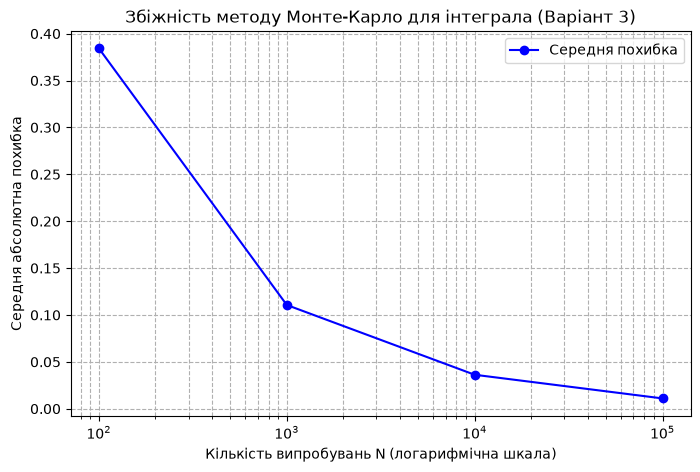

In [4]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(3)
exact = 4.0
a, b = 0.0, 2.0
n_values = [100, 1_000, 10_000, 100_000]
mean_errors = []

for N in n_values:
  errors = [
      abs((b - a) * (np.random.uniform(a, b, N) ** 3).mean() - exact)
      for _ in range(200)
  ]
  mean_errors.append(np.mean(errors))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    n_values,
    mean_errors,
    marker="o",
    linestyle="-",
    color="b",
    label="Середня похибка",
)
ax.set_xscale("log")
ax.set_xlabel("Кількість випробувань N (логарифмічна шкала)")
ax.set_ylabel("Середня абсолютна похибка")
ax.set_title("Збіжність методу Монте-Карло для інтеграла (Варіант 3)")
ax.grid(True, which="both", ls="--")
ax.legend()
plt.show()

## Відповіді на контрольні питання (для здачі)

* **Чому оцінка методом Монте-Карло — це, по суті, вибіркове середнє, і який саме результат Лекції 12 гарантує, що вона наближається до точного значення зі зростанням N?**
Оскільки ми обчислюємо середнє арифметичне значення функції (або індикаторів) для всіх згенерованих випадкових точок, це класичне вибіркове середнє. Його збіжність до істинного математичного сподівання (і відповідно до точного значення інтеграла чи площі) гарантує **Закон великих чисел**.
* **Чому вчетверо більша кількість випробувань дає лише вдвічі меншу похибку, а не вчетверо меншу, — де саме в формулі похибки з'являється корінь?**
Корінь з'являється у формулі стандартної похибки вибіркового середнього: $\sigma / \sqrt{N}$. Оскільки розмір вибірки $N$ стоїть під знаком квадратного кореня у знаменнику, збільшення $N$ у 4 рази дає зменшення похибки у $\sqrt{4} = 2$ рази.
* **Для варіанта типу "площа": чому частку точок усередині фігури потрібно множити саме на площу прямокутника-охоплення, а не залишати як кінцеву відповідь?**
Частка точок усередині фігури — це безрозмірна ймовірність (число від 0 до 1). Щоб перетворити її на абсолютну геометрічну величину (площу), цю частку необхідно помножити на загальну площу охоплюючого прямокутника, у межах якого рівномірно генерувалися точки.
* **Для варіанта типу "сподівання": чому саме .min(axis=1) чи .max(axis=1) (а не .min() чи .max() без axis) дає масив результатів окремо для кожного випробування, а не одне число для всей матриці кидків?**
Метод `np.random.randint(1, 7, size=(N, k))` генерує двовимірну матрицю розміром $N \times k$, де кожен рядок відповідає окремому незалежному випробуванню (експерименту з $k$ кидками). Виклик `.min(axis=1)` виконує операцію мінімуму окремо вздовж кожного рядка, формуючи масив із $N$ результатів (по одному на кожне випробування), тоді як метод без `axis` згорнув би всю матрицю в єдине глобальне число.